In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("Diabetes_prediction.csv")

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
0,2,115.863387,56.410731,24.336736,94.385783,26.455940,0.272682,20.100494,0
1,2,92.490122,70.615520,23.443591,138.652426,23.910167,0.665160,44.912281,0
2,1,88.141469,63.262618,23.404364,149.358082,21.948250,0.676022,48.247873,1
3,2,108.453101,67.793632,20.751580,108.751638,24.209304,0.289636,42.749868,0
4,1,127.849443,94.725685,22.603078,25.269987,32.997477,0.601315,32.797789,0


In [4]:
print("Shape:", df.shape)
df.dtypes

Shape: (1000, 9)


Pregnancies                   int64
Glucose                     float64
BloodPressure               float64
SkinThickness               float64
Insulin                     float64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                         float64
Diagnosis                     int64
dtype: object

In [5]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Diagnosis                   0
dtype: int64

In [6]:
feature_cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
                "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
X = df[feature_cols]
y = df["Diagnosis"]

print("Target distribution:")
print(y.value_counts())

Target distribution:
Diagnosis
0    694
1    306
Name: count, dtype: int64


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples:     {X_test.shape[0]}")
print("Feature scaling applied (StandardScaler)")

Training samples: 800
Test samples:     200
Feature scaling applied (StandardScaler)


In [8]:
perceptron = Perceptron(max_iter=1000, random_state=42, tol=1e-3)
perceptron.fit(X_train_scaled, y_train)

y_pred = perceptron.predict(X_test_scaled)
print("Perceptron model trained.")
print("Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

Perceptron model trained.
Accuracy: 63.0 %


In [9]:
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Non-Diabetic", "Diabetic"]))

Classification Report:
              precision    recall  f1-score   support

Non-Diabetic       0.70      0.83      0.76       139
    Diabetic       0.31      0.18      0.23        61

    accuracy                           0.63       200
   macro avg       0.51      0.50      0.49       200
weighted avg       0.58      0.63      0.60       200



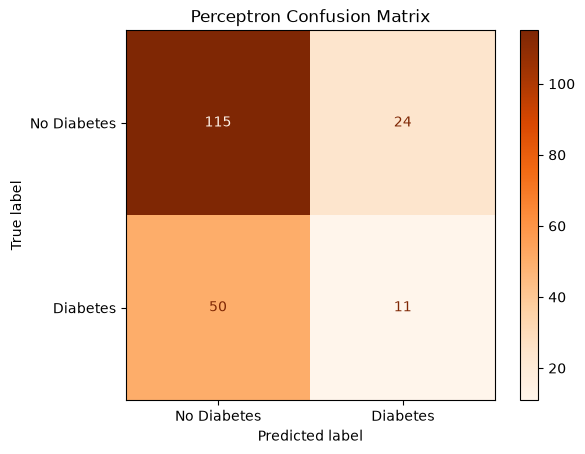

In [10]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
).plot(cmap="Oranges")
plt.title("Perceptron Confusion Matrix")
plt.show()

In [11]:
print("Effect of max_iter on Perceptron accuracy:")
for iters in [10, 50, 100, 500, 1000]:
    p = Perceptron(max_iter=iters, random_state=42, tol=1e-3)
    p.fit(X_train_scaled, y_train)
    acc = accuracy_score(y_test, p.predict(X_test_scaled))
    print(f"  max_iter={iters:>5}  |  Accuracy: {acc*100:.2f}%")

Effect of max_iter on Perceptron accuracy:
  max_iter=   10  |  Accuracy: 63.00%
  max_iter=   50  |  Accuracy: 63.00%
  max_iter=  100  |  Accuracy: 63.00%
  max_iter=  500  |  Accuracy: 63.00%
  max_iter= 1000  |  Accuracy: 63.00%


Perceptron Feature Weights (absolute value sorted):
                 Feature    Weight
                 Insulin  3.285828
           SkinThickness -2.426951
DiabetesPedigreeFunction -2.041816
           BloodPressure -1.775095
                 Glucose  1.186021
             Pregnancies  0.700219
                     BMI -0.630844
                     Age -0.175704


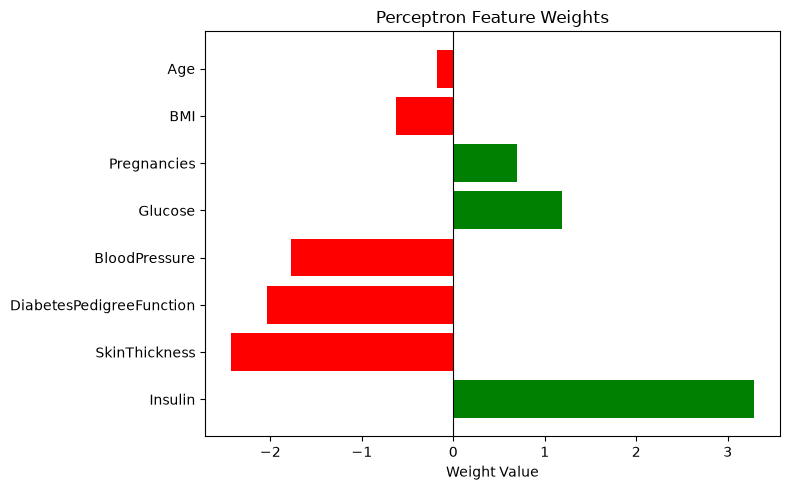

In [12]:
weights_df = pd.DataFrame({
    "Feature": feature_cols,
    "Weight": perceptron.coef_[0]
}).sort_values("Weight", key=abs, ascending=False)

print("Perceptron Feature Weights (absolute value sorted):")
print(weights_df.to_string(index=False))

plt.figure(figsize=(8, 5))
colors = ["green" if w > 0 else "red" for w in weights_df["Weight"]]
plt.barh(weights_df["Feature"], weights_df["Weight"], color=colors)
plt.axvline(x=0, color="black", linewidth=0.8)
plt.xlabel("Weight Value")
plt.title("Perceptron Feature Weights")
plt.tight_layout()
plt.show()